# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:

# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv") #completa el código
usage = pd.read_csv("/datasets/usage.csv")  #completa el código

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print()
print(users.isna().sum()/len(users)*100)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print()
print(usage.isna().sum()/len(usage)*100)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
   Para el DataFrame de users encontramos nulos en la columna `city`, que representan el 11.7% y la columna `churn_date` que representan el 88.3%.

  
   Para el DataFrame de usage encontramos nulos en la columna de `date` que representan un 0.1%, en la columna `duration`, que representan un 55.1% y la columna `length` que representan un 44.7%.
  
- Indica qué harías: ¿imputar, eliminar, ignorar?
  Para el Dataframe de users, en la columna de city dejaría los valores como **NaN** ya que no tenemos la certeza de esa información, e ignoraría la columna `churn_date` debido a que los valores nulos aquí indican que los clientes están activos.

  Para el DataFrame de usage, en la columna de `date` dejaría los valores como nulos porque es un porcentaje muy pequeño y no es una columna crítica para el análisis, e ignoraría los valores nulos en las columnas `duration` y `length`, ya que estos nulos son estructuralmente esperados, cada fila solo puede tener un valor en una de estas columnas dependiendo del tipo de evento: text=length - call=duration. 
   

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users[["user_id","age"]].describe()


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` no tiene valores nulos y las demás métricas no son relevantes, estos valores son identificadores.
- La columna `age` tiene valores inválidos en el mínimo (-999).

In [13]:
# explorar columnas numéricas de usage
usage[["user_id","id","duration","length"]].describe()

,user_id,id,duration,length
count,40000.000000,40000.00000,17924.000000,22104.000000
mean,12002.405975,20000.50000,5.202237,52.127398
std,1157.279564,11547.14972,6.842701,56.611183
min,10000.000000,1.00000,0.000000,0.000000
25%,10996.000000,10000.75000,1.437500,37.000000
50%,12013.000000,20000.50000,3.500000,50.000000
75%,13005.000000,30000.25000,6.990000,64.000000
max,13999.000000,40000.00000,120.000000,1490.000000


- Las columnas `id` y `user_id` no tienen valores nulos y las demás métricas no son relevantes, estos valores son identificadores.
- Las columnas `duration` y `length` tienen valores muy altos que podrían ser outliers.

- La columna `city` tiene 469 valores nulos y la ciudad que más se repite es **Bogotá.**
- La columna `plan` no tiene valores nulos y el plan que más se repite es **Básico.**

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


In [15]:
users["city"].unique() 

array(['Medellín', '?', 'CDMX', 'Bogotá', 'GDL', 'MTY', nan, 'Cali'],
      dtype=object)

In [16]:
# explorar columna categórica de usage
usage['type'].describe() # completa el código

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` no tiene valores nulos y la categoría que más se repite es **text**


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
En el DataFrame users, en la columna de `age` se encontraron sentinels (-999) y en la columna `city` se encontraron sentinels (?).

- ¿Qué acción tomarías?
En este caso, en la columna de `age` reemplazaría los sentinels con la mediana de los datos y en la columna de `city` reemplazaría los sentinels con **NaN** para no interferir con el formato de las columnas.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"],errors="coerce") # completa el código

In [18]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"],errors="coerce") # completa el código

In [19]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

In [20]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


En `reg_date`, encontramos un valor imposible (2026) que corresponde a un año no transcurrido.

In [21]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

In [22]:
usage[usage["date"].isna()].head(10)

,id,user_id,type,date,duration,length
2854,2855,12193,text,NaT,NaN,64.0
3443,3444,10775,text,NaT,NaN,69.0
3808,3809,10916,text,NaT,NaN,23.0
3987,3988,12175,call,NaT,2.43,NaN
4114,4115,12527,text,NaT,NaN,67.0
6287,6288,13676,call,NaT,1.64,NaN
6445,6446,12553,text,NaT,NaN,39.0
6584,6585,12542,text,NaT,NaN,43.0
7879,7880,11347,text,NaT,NaN,35.0
8204,8205,10099,text,NaT,NaN,41.0


En `date`, tenemos 50 valores nulos que no siguen un patrón en particular, que en este caso podemos ignorar y dejarlos como **NaT.** 
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
En `reg_date` de users, encontramos un valor imposible (2026) que corresponde a un año no transcurrido.

- ¿Qué harías con ellas?
En este caso, reemplazaría este valor por **NaT** para no interferir con el formato de fecha y no perder información valiosa de las otras columnas.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [23]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"][users["age"]>0].median()
users['age'] = users['age'].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [24]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?",np.nan)

# Verificar cambios
users["city"].unique() 

array(['Medellín', nan, 'CDMX', 'Bogotá', 'GDL', 'MTY', 'Cali'],
      dtype=object)

In [25]:
# Marcar fechas futuras como NA para reg_date
users.loc[users["reg_date"].dt.year == 2026,"reg_date"] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.unique()

array([2022.,   nan, 2023., 2024.])

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [26]:
# Verificación MAR en usage (Missing At Random) para duration
usage.loc[usage["duration"].isna(),"type"]

1        text
2        text
8        text
9        text
11       text
         ... 
39979    text
39981    text
39985    text
39987    text
39998    text
Name: type, Length: 22076, dtype: object

In [27]:
# Verificación MAR en usage (Missing At Random) para length
usage.loc[usage["length"].isna(),"type"]

0        call
3        call
4        call
5        call
6        call
         ... 
39994    call
39995    call
39996    call
39997    call
39999    call
Name: type, Length: 17896, dtype: object

In [28]:
# Verificación de valores unicos en type
usage["type"].unique()

array(['call', 'text'], dtype=object)

Se evidencia que los valores nulos en `duration` y `length` son de tipo **MAR** y dependen de la columna `type` si es `call` va a tener valores en `duration` y si es `text` va a tener valores en `length` y valores nulos en la columna contraria.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [29]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario

usage_agg = usage.groupby("user_id").agg(mensajes=("is_text","sum"),llamadas=("is_call","sum"),duracion=("duration","sum")).reset_index()


# observar resultado
usage_agg.head(3)

,user_id,mensajes,llamadas,duracion
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [30]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"mensajes":"cant_mensajes","llamadas":"cant_llamadas","duracion":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [31]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users,usage_agg,on="user_id",how="inner")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [32]:

# Resumen estadístico de las columnas numéricas

col_numericas = user_profile[["age","cant_mensajes","cant_llamadas","cant_minutos_llamada"]]
col_numericas.describe()



,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.138285,5.524381,4.478120,23.317054
std,17.691541,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [33]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts()/len(user_profile["plan"])*100

Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

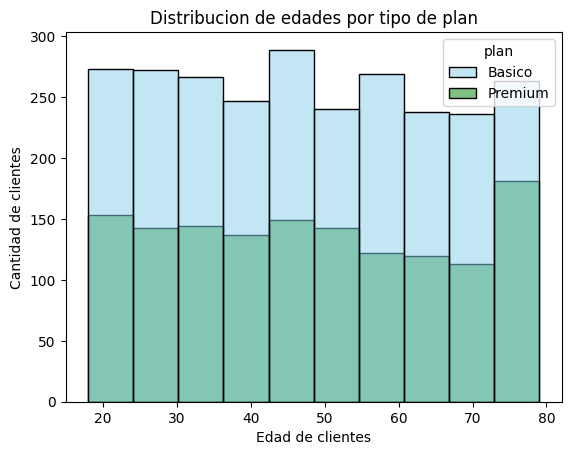

In [34]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,bins=10,x="age",hue="plan",palette=['skyblue','green'])

plt.xlabel("Edad de clientes")
plt.ylabel("Cantidad de clientes")
plt.title("Distribucion de edades por tipo de plan")
plt.show()

💡Insights: 
- La proporción del plan básico destaca en clientes de mediana edad (40-50 años aprox.) y la proporción para el plan premium destaca en clientes mayores (70-80 años aprox.)

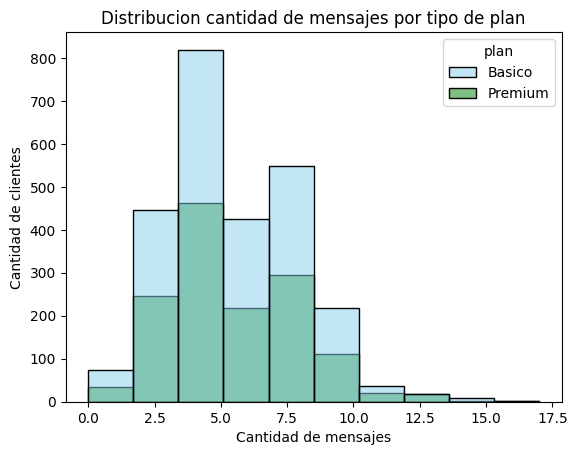

In [35]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile,bins=10,x="cant_mensajes",hue="plan",palette=['skyblue','green'])

plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de clientes")
plt.title("Distribucion cantidad de mensajes por tipo de plan")
plt.show()

💡Insights: 
- En este caso se evidencia que la proporción de clientes destaca en ambos casos, tanto en el plan básico como en el plan premium, siguen un patrón de distribución similar, con una cantidad baja de mensajes de 3 a 5 mensajes, siendo el plan básico notablemente el que acumula la mayoría de clientes.

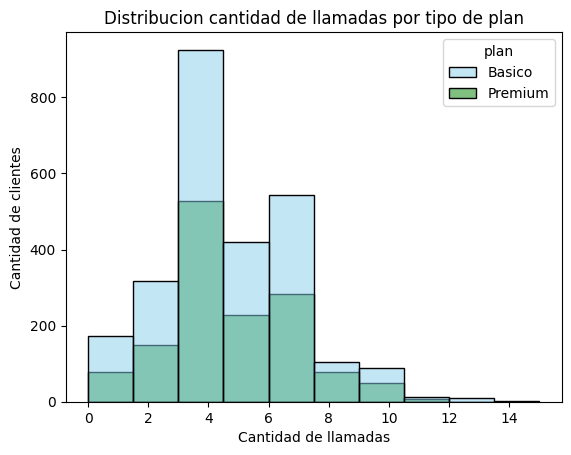

In [36]:
# Histograma para visualizar la cant_llamadas

sns.histplot(data=user_profile,bins=10,x="cant_llamadas",hue="plan",palette=['skyblue','green'])

plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de clientes")
plt.title("Distribucion cantidad de llamadas por tipo de plan")
plt.show()


💡Insights: 
- El gráfico nos muestra que la proporción de clientes destaca en ambos casos, tanto en el plan básico como en el plan premium, siguen un patrón de distribución similar, con una cantidad baja de llamadas de 3 a 5, siendo el plan básico notablemente el que acumula la mayoría de clientes.

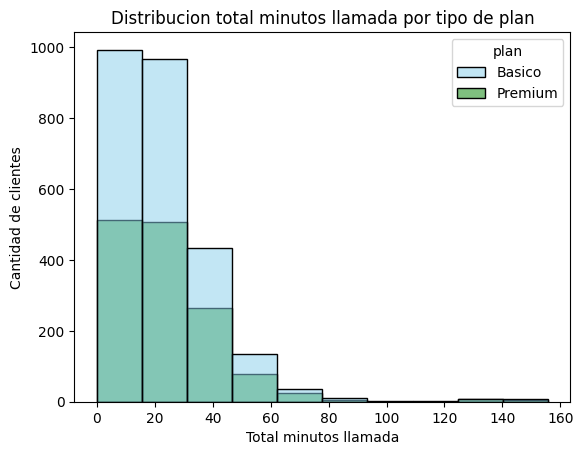

In [37]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile,bins=10,x="cant_minutos_llamada",hue="plan",palette=['skyblue','green'])

plt.xlabel("Total minutos llamada")
plt.ylabel("Cantidad de clientes")
plt.title("Distribucion total minutos llamada por tipo de plan")
plt.show()

💡Insights: 
- Nuevamente vemos que la proporción de clientes destaca en ambos casos, tanto en el plan básico como en el plan premium, y siguen un patrón de distribución similar, con una cantidad total de minutos de 0 a 30, siendo el plan básico el que acumula la mayoría de clientes, casi por el doble al plan premium.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

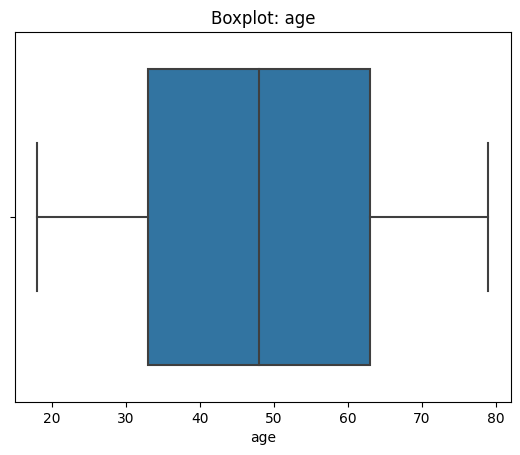

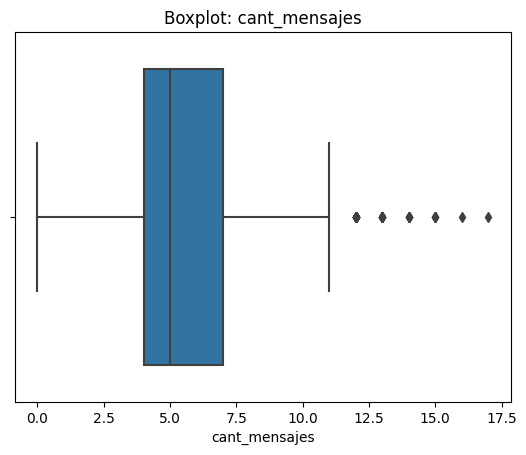

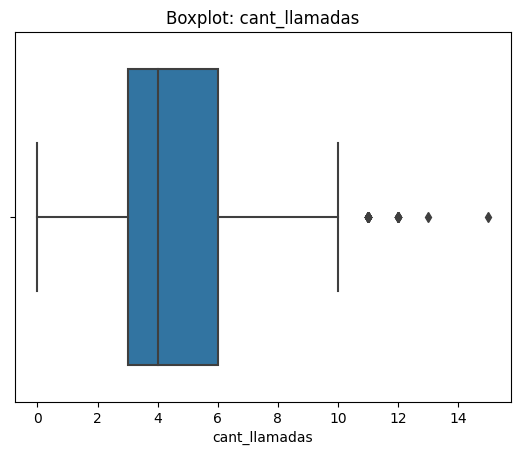

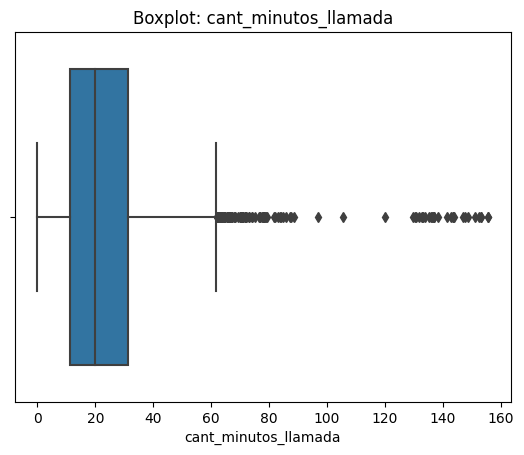

In [38]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: No presenta outliers, tiene una distribución simétrica.
- cant_mensajes: Presenta varios outliers por encima del límite superior.
- cant_llamadas: Presenta algunos outliers por encima del límite superior.
- cant_minutos_llamada: Presenta muchos outliers por encima del límite superior.

In [39]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
                    

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    IQR = q3 - q1
    limite_superior = q3 + 1.5 * IQR

    print (f'Limites: {col}')
    print("Q1:",q1)
    print("Q3",q3)
    print("IQR",IQR)
    print("Limite superior:",limite_superior)
    print()



Limites: cant_mensajes
Q1: 4.0
Q3 7.0
IQR 3.0
Limite superior: 11.5

Limites: cant_llamadas
Q1: 3.0
Q3 6.0
IQR 3.0
Limite superior: 10.5

Limites: cant_minutos_llamada
Q1: 11.12
Q3 31.415
IQR 20.295
Limite superior: 61.8575



In [40]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: Se recomienda mantener los outliers ya que representan un comportamiento real de los usuarios y el valor máximo no está muy lejano del límite superior (5.5 unidades).
- cant_llamadas: Se recomienda mantener los outliers ya que representan un comportamiento real de los usuarios y el valor máximo no está muy lejano del límite superior (4.5 unidades).
- cant_minutos_llamada: Se recomienda hacer una winsorización para capar los outliers que en este caso están muy por encima del límite superior y así estabilizar las métricas.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [41]:
# Crear columna grupo_uso
def grupo_uso (row):
    llamadas = row["cant_llamadas"]
    mensajes = row["cant_mensajes"]
    if llamadas >10 and mensajes >10:
        return "Alto uso"
    elif llamadas >5 and llamadas <=10 and mensajes >5 and mensajes <=10:
        return "Uso medio"
    else:
        return "Bajo uso"

user_profile["grupo_uso"] = user_profile.apply(grupo_uso, axis = 1)

In [42]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Bajo uso
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Bajo uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Bajo uso
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Bajo uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [43]:
# Crear columna grupo_edad
def grupo_edad (row):
    edad = row["age"]
    if edad <30:
        return "Joven"
    elif edad <= 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile["grupo_edad"] = user_profile.apply(grupo_edad, axis = 1)

In [44]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Bajo uso,Adulto
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Bajo uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Bajo uso,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Bajo uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

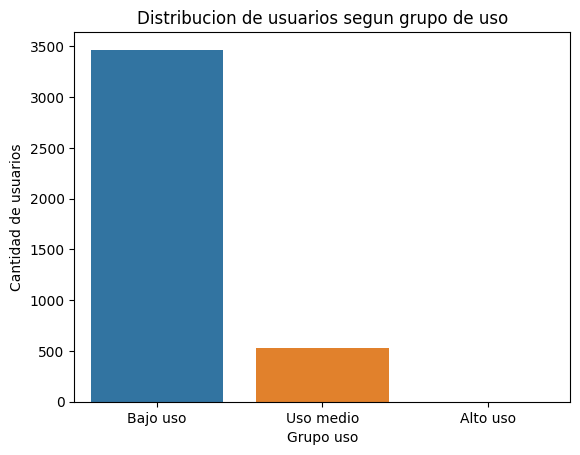

In [45]:
# Visualización de los segmentos por uso
sns.countplot(data = user_profile,x = "grupo_uso")

plt.xlabel("Grupo uso")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribucion de usuarios segun grupo de uso")
plt.show()

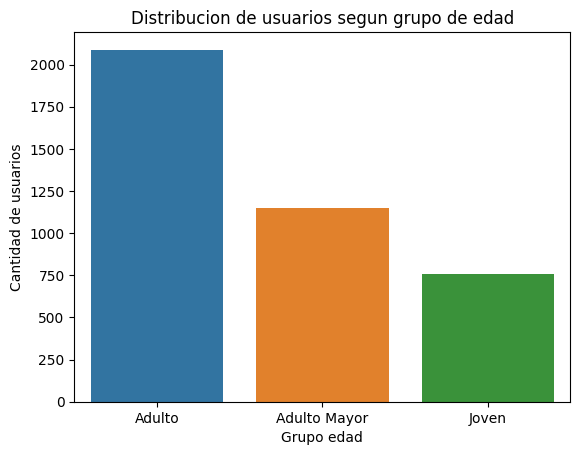

In [46]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile,x = "grupo_edad")

plt.xlabel("Grupo edad")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribucion de usuarios segun grupo de edad")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Originalmente, detectamos que en el df de `users` en la columna `city` presenta tanto valores nulos que representan el 11.7% como valores inválidos "?".
En el df de usage la columna `date` presenta valores nulos que representan el 0.12%. Se identificaron nulos en la columnas `churn_date`, `duration` y `length`, pero corresponden a situaciones esperadas del negocio (cliente activo, o tipo de evento que fue solo llamada/mensaje), no a errores reales.

También se realizó la detección de valores inválidos y sentinels, para el df users en la columna de age tiene valores inválidos (-999).

Se encontró que en el df de users en la columna de `reg_date` había un valor imposible, el año 2026 que corresponde a un año no transcurrido.


🔍 **Segmentos por Edad**
Los datos se segmentaron por la distribución de usuarios según grupo de edad, donde la categoría Adulto destaca con la mayor cantidad de usuarios, seguida por Adulto Mayor y finalizando con Joven.
 

📊 **Segmentos por Nivel de Uso**
También se segmentaron por la distribución de usuarios según uso, donde la categoría Bajo uso destaca por acumular la mayor cantidad de usuarios, superando por mucho a las demás categorías.

➡️ Esto sugiere que los segmentos más valiosos por nivel de uso son el segmento "uso medio", porque combina un volumen razonable de usuarios con mayor que el grupo de bajo uso, y por edad es el segmento de "adulto", por ser la categoría que contiene más usuarios. Es importante aclarar que, para confirmar si estos dos segmentos coinciden en los mismos usuarios, se debe realizar un análisis cruzado, el cual no se realizó en este proyecto.


💡 **Recomendaciones**
Se recomienda analizar el grupo de usuarios outliers en cant_minutos_llamada para ajustar planes enfocados a solo llamadas o promociones de paquetes de llamadas. Para el tipo de plan se sugiere revisar los beneficios y prestaciones de cada uno para ajustarlos al segmento de edad en el que destacan, por ejemplo, para los adultos mayores que prefieren el plan premium, se podría pensar en planes con servicios ilimitados y, por último sería conveniente realizar un análisis donde se cruce el segmento de uso medio y el de adulto para determinar si coinciden y poder direccionar las campañas a estos usuarios para incrementar la proporción.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`